# CP asymmetry study

This notebook extends the B -> hhh workflow toward a simple charge-asymmetry measurement. The goal is not yet a precision CP-violation result, but a clean demonstration of how B+ and B- candidates can be separated and compared.


## Physics motivation

A direct CP asymmetry compares the decay rates of a process and its charge-conjugate process. In a simplified counting analysis, an integrated raw asymmetry can be estimated from the observed B- and B+ yields:

$$A_{CP}^{raw} = \frac{N(B^-) - N(B^+)}{N(B^-) + N(B^+)}.$$

A publication measurement would also correct for detector, production, trigger, and background effects. Here we keep the estimator deliberately transparent.


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep the matplotlib font cache inside the project so notebook runs stay quiet
# even when the default cache directory is not writable.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "B2HHH_MagnetDown.root"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

DATA_PATH

PosixPath('/Users/yanisidir/Projects/lhcb-b2hhh-analysis/data/raw/B2HHH_MagnetDown.root')

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src.physics.selection import load_b2hhh_dataframe, add_b_mass, apply_baseline_selection
from src.plotting.mass_plots import set_hep_style

set_hep_style()


## Load data and reconstruct candidates

The same ROOT file, invariant-mass reconstruction, and baseline quality/PID cuts are used as in the previous notebooks. This keeps the charge comparison aligned with the mass and ML studies.


In [3]:
df = load_b2hhh_dataframe(DATA_PATH)
df = add_b_mass(df)
df_sel = apply_baseline_selection(df)

print(f"Loaded candidates:     {len(df):,}")
print(f"Selected candidates:   {len(df_sel):,}")
df_sel.head()


Loaded candidates:     5,135,823
Selected candidates:   1,645


,H1_PX,H1_PY,H1_PZ,H2_PX,H2_PY,H2_PZ,H3_PX,H3_PY,H3_PZ,H1_Charge,...,H3_Charge,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_VertexChi2,B_FlightDistance,B_mass
5911,409.597326,-922.895885,20897.310967,1203.071583,-1920.154667,40475.734267,-3459.363958,-2564.626154,75809.047870,-1,...,1,0.922096,0.950725,0.921754,0.059316,0.254305,0.092939,1.044176,53.008846,5278.782080
7561,1896.131812,342.165476,13004.358365,-212.269027,2315.053951,29215.421432,3919.152618,2803.269146,50026.628572,-1,...,1,0.803463,0.769137,0.964152,0.094286,0.038924,0.132662,1.234878,25.028023,5280.889118
8171,2639.151502,4945.908581,36593.572489,1746.893777,2578.755924,19941.038258,2752.570307,6924.039031,87480.913013,1,...,-1,0.586932,0.792148,0.619050,0.093519,0.045532,0.617080,1.396345,26.784880,5310.000362
14006,-580.924639,-3482.868924,42314.120655,1329.515702,-2999.949560,52082.765074,-2272.459558,-2821.365130,73606.673218,-1,...,1,0.953703,0.943361,0.702081,0.114240,0.166630,0.415309,3.868593,21.125746,5252.199904
17076,4662.947762,-1502.073656,27549.868520,-347.144740,-1624.302106,6795.955362,2865.033662,-987.027245,18183.793931,1,...,-1,0.973362,0.693893,0.668686,0.119986,0.045107,0.031975,2.847910,29.216699,5299.993524


## Split B+ and B- candidates

The total reconstructed candidate charge is the sum of the three daughter-track charges. Candidates with total charge +1 are treated as B+ candidates, and candidates with total charge -1 as B- candidates.


In [4]:
df_sel["total_charge"] = (
    df_sel["H1_Charge"] + df_sel["H2_Charge"] + df_sel["H3_Charge"]
)

b_plus = df_sel.loc[df_sel["total_charge"] == 1].copy()
b_minus = df_sel.loc[df_sel["total_charge"] == -1].copy()

print(f"B+ candidates: {len(b_plus):,}")
print(f"B- candidates: {len(b_minus):,}")
print(df_sel["total_charge"].value_counts().sort_index())


B+ candidates: 884
B- candidates: 761
total_charge
-1    761
 1    884
Name: count, dtype: int64


## Separate invariant-mass spectra

The two charge samples should show compatible B-mass structures if the reconstruction is consistent. Differences in total yield can indicate physics asymmetries, detector asymmetries, production asymmetries, or background differences.


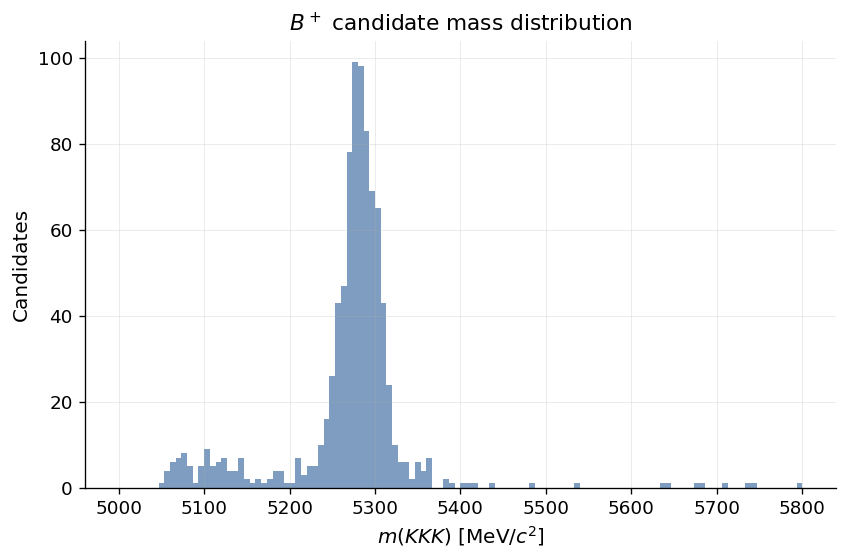

In [5]:
MASS_RANGE = (5000, 5800)
BINS = 120

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.hist(b_plus["B_mass"], bins=BINS, range=MASS_RANGE, histtype="stepfilled", alpha=0.72, color="#4c78a8")
ax.set_xlabel(r"$m(KK K)$ [MeV/$c^2$]")
ax.set_ylabel("Candidates")
ax.set_title(r"$B^+$ candidate mass distribution")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "B_plus_mass_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


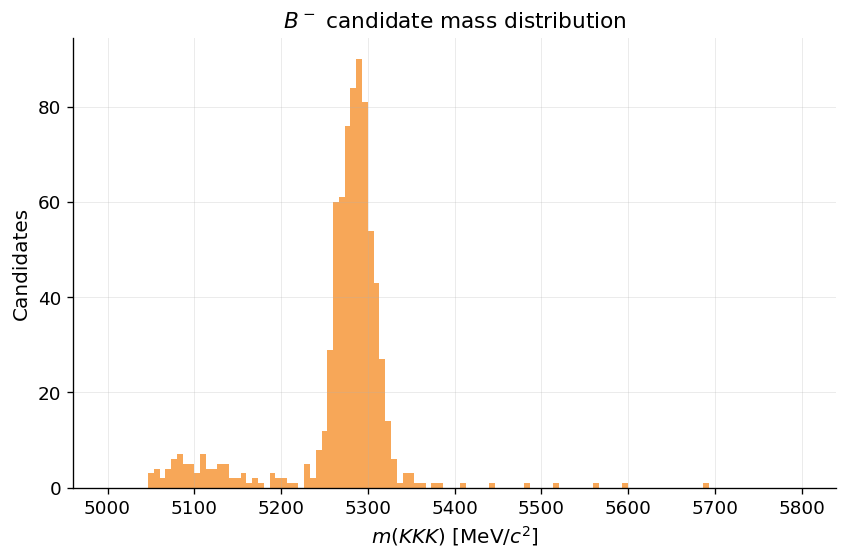

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.hist(b_minus["B_mass"], bins=BINS, range=MASS_RANGE, histtype="stepfilled", alpha=0.72, color="#f58518")
ax.set_xlabel(r"$m(KK K)$ [MeV/$c^2$]")
ax.set_ylabel("Candidates")
ax.set_title(r"$B^-$ candidate mass distribution")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "B_minus_mass_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## Overlay comparison

Overlaying the two charge spectra gives a direct visual check of charge-dependent differences across the mass window.


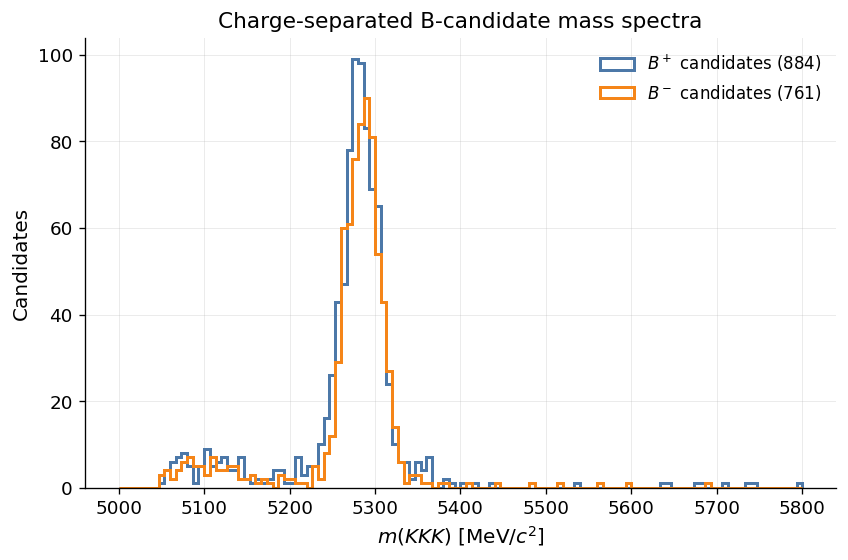

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.hist(
    b_plus["B_mass"],
    bins=BINS,
    range=MASS_RANGE,
    histtype="step",
    linewidth=1.8,
    color="#4c78a8",
    label=rf"$B^+$ candidates ({len(b_plus):,})",
)
ax.hist(
    b_minus["B_mass"],
    bins=BINS,
    range=MASS_RANGE,
    histtype="step",
    linewidth=1.8,
    color="#f58518",
    label=rf"$B^-$ candidates ({len(b_minus):,})",
)
ax.set_xlabel(r"$m(KK K)$ [MeV/$c^2$]")
ax.set_ylabel("Candidates")
ax.set_title(r"Charge-separated B-candidate mass spectra")
ax.legend(frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cp_mass_overlay.png", dpi=300, bbox_inches="tight")
plt.show()


## Integrated raw CP asymmetry

The raw asymmetry is evaluated in a narrow B-mass signal window to reduce combinatorial background dilution. This remains a simple observed-yield asymmetry, not a corrected physics measurement.


In [8]:
SIGNAL_WINDOW = (5270, 5290)

n_b_plus = b_plus["B_mass"].between(*SIGNAL_WINDOW).sum()
n_b_minus = b_minus["B_mass"].between(*SIGNAL_WINDOW).sum()

a_cp = (n_b_minus - n_b_plus) / (n_b_minus + n_b_plus)

print(f"Signal window: {SIGNAL_WINDOW[0]}-{SIGNAL_WINDOW[1]} MeV/c^2")
print(f"N(B+) = {n_b_plus:,}")
print(f"N(B-) = {n_b_minus:,}")
print(f"Raw integrated A_CP = {a_cp:.5f}")


Signal window: 5270-5290 MeV/c^2
N(B+) = 282
N(B-) = 246
Raw integrated A_CP = -0.06818


### Superseded by the fitted asymmetry

This counting estimate is a first look, kept here because it makes the definition
concrete. It is **not** the result quoted in the report: counting inside a fixed
window includes the background under the peak, and the background fraction need
not be the same for the two charges.

The result of record comes from fitting the two charge spectra separately,

```bash
python scripts/run_charge_separated_fits.py
```

which gives `A_raw = -0.0353 +/- 0.0290 (stat.) +/- 0.0323 (syst.)`. See
`results/fits/charge_separated/raw_asymmetry.json` and Sec. 7 of the report.

## Interpretation

The numerical value above is a first charge-asymmetry diagnostic. A realistic CP-analysis workflow would next fit the B+ and B- mass spectra separately, subtract backgrounds, combine magnet polarities, and correct detector-induced charge asymmetries before interpreting the result as a physical CP asymmetry.
